In [ ]:
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision.utils as vutils
from sklearn.linear_model import Ridge
from PIL import Image
import seaborn as sns

from compcats.datasets.fmri import nsd
from compcats.encoder import encode
from compcats.utils import model_utils, responsecomparison_utils as rc_utils
from compcats.utils import reliability_utils as rel_utils
from compcats.models import  resnet50_openaiclip

sys.path.append('../preprint')
from preprint import paths
from preprint import main_analysis as ma

RESULTS_DIR = 'results/'
os.makedirs(RESULTS_DIR, exist_ok=True)
PLOTS_DIR = 'plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

MODELS_DIR = '/Users/adipani3/projects/catsel/comparing-category-selectivity/preprint/models'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
subject = 1
froi = 'V1'
rthreshold = 0.4

train_subset = 485
test_subset = 515

model = resnet50_openaiclip.get_model()

In [57]:
y_train, images_df = nsd.get_betas(
    paths.NSD_DIR,
    subject,
    froi,
    None,
    subset=train_subset,
    voxels=True,
    repetition_mean=False
)
voxel_reliabilities = rel_utils.get_voxelwise_splithalf_correlation(y_train)
reliability_mask = voxel_reliabilities > rthreshold
print(f'Number of reliable voxels in subject {subject} {froi}: {reliability_mask.sum().item()}')
voxel_reliabilities = voxel_reliabilities[reliability_mask]
print(f'Voxel reliabilities: mean={voxel_reliabilities.mean().item():.3f}, std={voxel_reliabilities.std().item():.3f}')
y_train = y_train[:, :, reliability_mask]
print(f'Population reliability, univariate: {rel_utils.get_voxelmean_splithalf_correlation(y_train):.3f}')
print(f'Population reliability, multivariate: {rel_utils.get_rdm_splithalf_correlation(y_train):.3f}')
y_train = y_train.mean(axis=1)

y_test, images_df_test = nsd.get_betas(
    paths.NSD_DIR,
    subject,
    froi,
    None,
    subset=test_subset,
    voxels=True,
    repetition_mean=True
)
y_test = y_test[:, reliability_mask]
assert y_test.shape[1] == y_train.shape[1], "Train and test voxel counts do not match"

# Move to CPU numpy arrays
y_train = y_train.cpu().numpy()
y_test = y_test.cpu().numpy()

Number of reliable voxels in subject 1 V1: 874
Voxel reliabilities: mean=0.563, std=0.094
Population reliability, univariate: 0.571
Population reliability, multivariate: 0.481


In [62]:
layers = [
    'layer1.0.conv3',
    'layer1.1.conv3',
    'layer2.0.conv3',
    'layer2.1.conv3',
    'layer2.2.conv3',
    'layer2.3.conv3',
    'layer3.0.conv3',
]
alpha = 0.1

100%|██████████| 1/1 [00:14<00:00, 14.85s/it]


Layer: layer1.0.conv3
Flattened train activations shape: torch.Size([485, 802816])
Flattened test activations shape: torch.Size([515, 802816])
Test Pearson's r: 0.430 ± 0.101
Test RDM correlation: 0.264


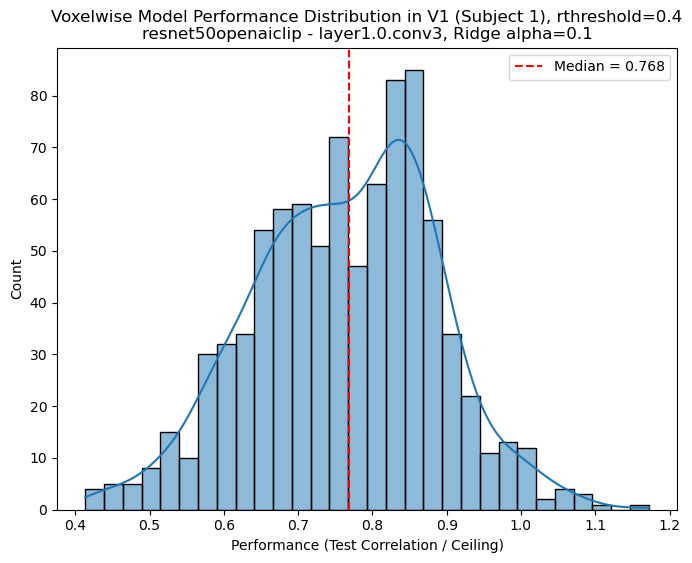

-----------------------------------------


Layer: layer1.1.conv3
Flattened train activations shape: torch.Size([485, 802816])
Flattened test activations shape: torch.Size([515, 802816])
Test Pearson's r: 0.485 ± 0.103
Test RDM correlation: 0.387


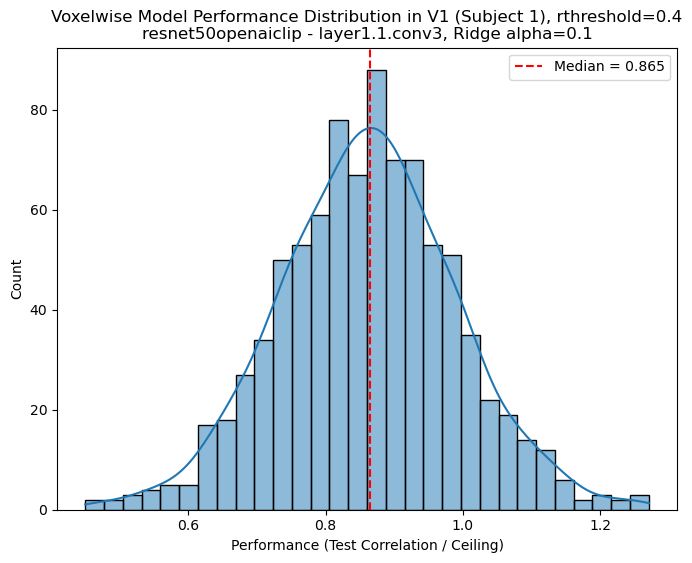

-----------------------------------------


Layer: layer2.0.conv3
Flattened train activations shape: torch.Size([485, 401408])
Flattened test activations shape: torch.Size([515, 401408])
Test Pearson's r: 0.500 ± 0.115
Test RDM correlation: 0.367


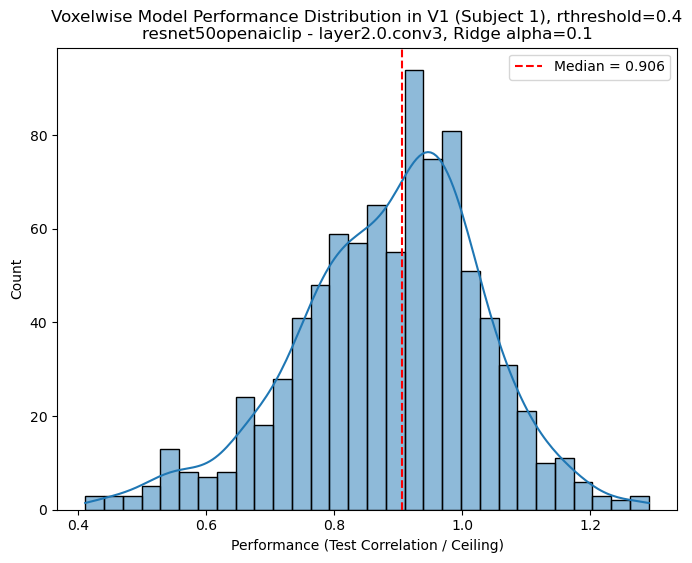

-----------------------------------------


Layer: layer2.1.conv3
Flattened train activations shape: torch.Size([485, 401408])
Flattened test activations shape: torch.Size([515, 401408])
Test Pearson's r: 0.513 ± 0.115
Test RDM correlation: 0.456


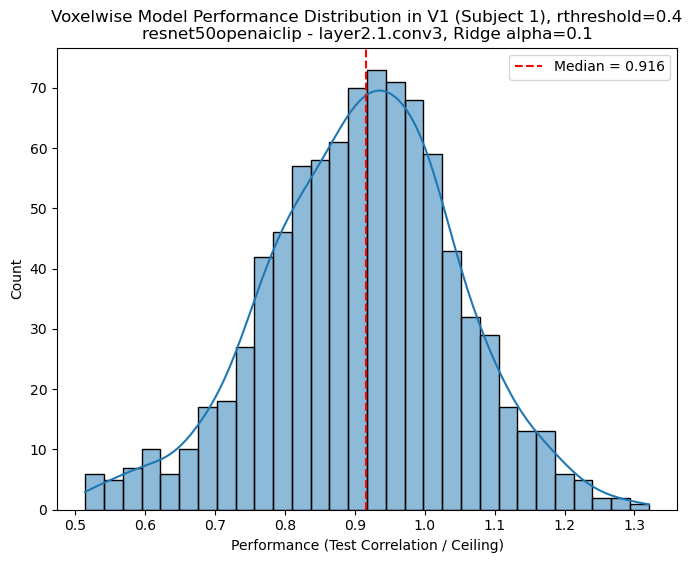

-----------------------------------------


Layer: layer2.2.conv3
Flattened train activations shape: torch.Size([485, 401408])
Flattened test activations shape: torch.Size([515, 401408])
Test Pearson's r: 0.472 ± 0.119
Test RDM correlation: 0.386


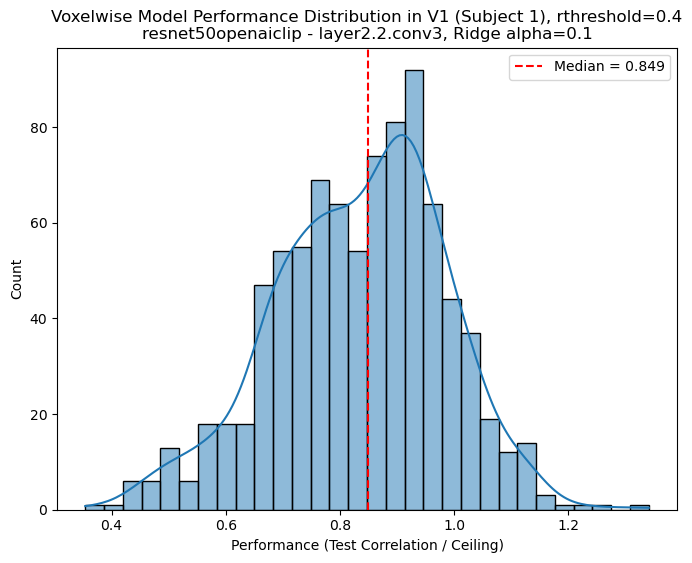

-----------------------------------------


Layer: layer2.3.conv3
Flattened train activations shape: torch.Size([485, 401408])
Flattened test activations shape: torch.Size([515, 401408])
Test Pearson's r: 0.445 ± 0.128
Test RDM correlation: 0.359


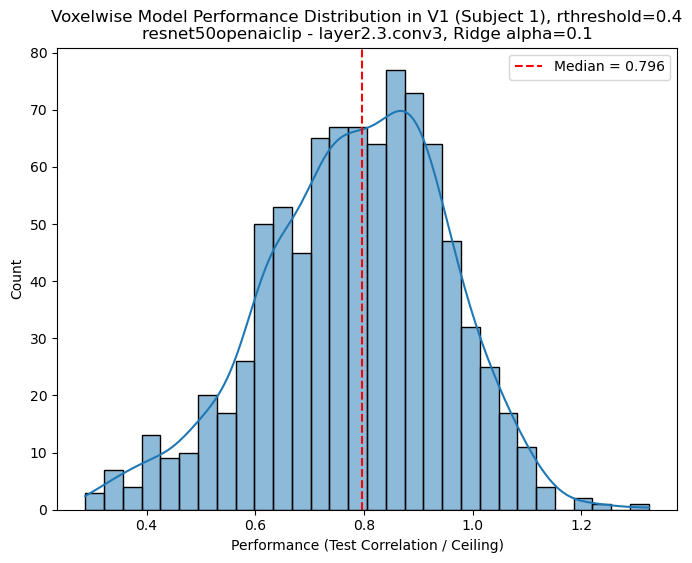

-----------------------------------------


Layer: layer3.0.conv3
Flattened train activations shape: torch.Size([485, 200704])
Flattened test activations shape: torch.Size([515, 200704])
Test Pearson's r: 0.423 ± 0.127
Test RDM correlation: 0.291


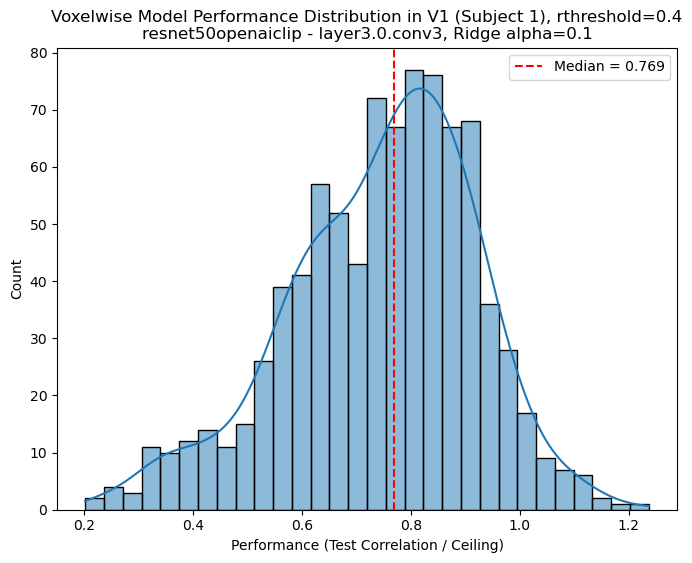

-----------------------------------------




In [63]:
x_train_dict = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.NSD_DIR,
    model,
    layers,
    'nsd',
    subset=train_subset
)
x_test_dict = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.NSD_DIR,
    model,
    layers,
    'nsd',
    subset=test_subset
)

for layer in layers:
    print(f'Layer: {layer}')
    x_train = x_train_dict[layer]
    x_test = x_test_dict[layer]
    # Flatten activations
    x_train = x_train.flatten(start_dim=1)
    x_test = x_test.flatten(start_dim=1)
    print(f'Flattened train activations shape: {x_train.shape}')
    print(f'Flattened test activations shape: {x_test.shape}')

    # Move to CPU numpy arrays
    x_train = x_train.cpu().numpy()
    x_test = x_test.cpu().numpy()

    trained_encoder, train_metrics, test_metrics = encode.fit_eval_mapper(
        Ridge(alpha=alpha),
        x_train,
        y_train,
        x_test,
        y_test,
        metric='all'
    )
    print(f"Test Pearson's r: {test_metrics['pearsonr'].mean():.3f} ± {test_metrics['pearsonr'].std():.3f}")
    print(f'Test RDM correlation: {test_metrics["rdmr"]:.3f}')
    # Plot performance per voxel
    voxelwise_test_univariate_corr = test_metrics['pearsonr']
    voxelwise_ceiling = voxel_reliabilities.copy()
    voxelwise_performance = voxelwise_test_univariate_corr / voxelwise_ceiling
    # Plot a distribution of voxelwise performance using searborn and make distribution plot
    # Also plot a line for median
    plt.figure(figsize=(8, 6))
    sns.histplot(voxelwise_performance, bins=30, kde=True)
    plt.axvline(np.median(voxelwise_performance), color='r', linestyle='--', label=f'Median = {np.median(voxelwise_performance):.3f}')
    plt.title(f'Voxelwise Model Performance in {froi} (Subject {subject})')
    plt.xlabel('Performance (Test Correlation / Ceiling)')
    plt.ylabel('Count')
    plt.title(f'Voxelwise Model Performance Distribution in {froi} (Subject {subject}), rthreshold={rthreshold}\n{model.name} - {layer}, Ridge alpha={alpha}')
    plt.legend()
    # plt.savefig(os.path.join(PLOTS_DIR, f'subject{subject}_{froi}_voxelwise_performance_distribution.png'))
    plt.show()
    print('-----------------------------------------\n\n')

In [67]:
layer = 'layer2.1.conv3'
alphas = [0.001, 0.01, 0.1, 1., 10., 100.]

Flattened train activations shape: torch.Size([485, 401408])
Flattened test activations shape: torch.Size([515, 401408])
Alpha: 0.001


/Users/adipani3/Softwares/miniconda3/envs/catsel/lib/python3.12/site-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=6.83728e-09): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


Test Pearson's r: 0.513 ± 0.115
Test RDM correlation: 0.456


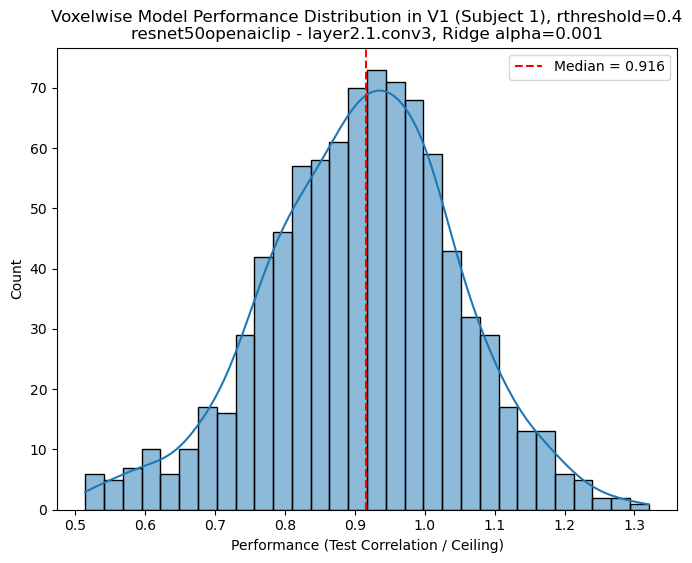

-----------------------------------------


Alpha: 0.01
Test Pearson's r: 0.513 ± 0.115
Test RDM correlation: 0.456


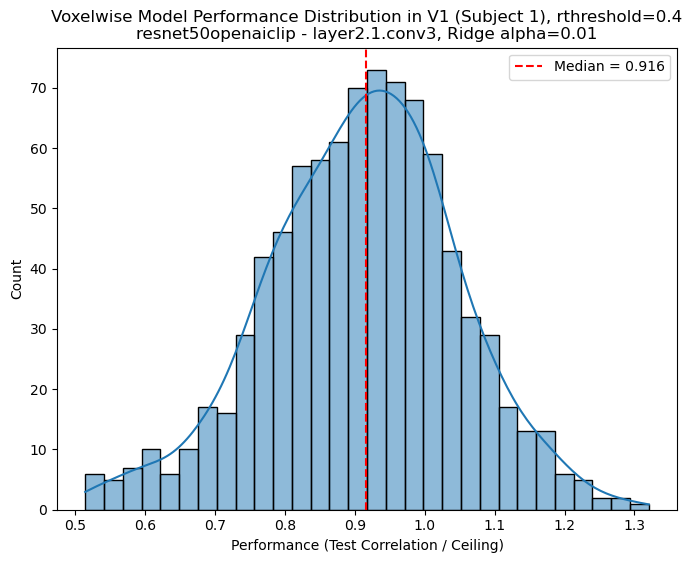

-----------------------------------------


Alpha: 0.1
Test Pearson's r: 0.513 ± 0.115
Test RDM correlation: 0.456


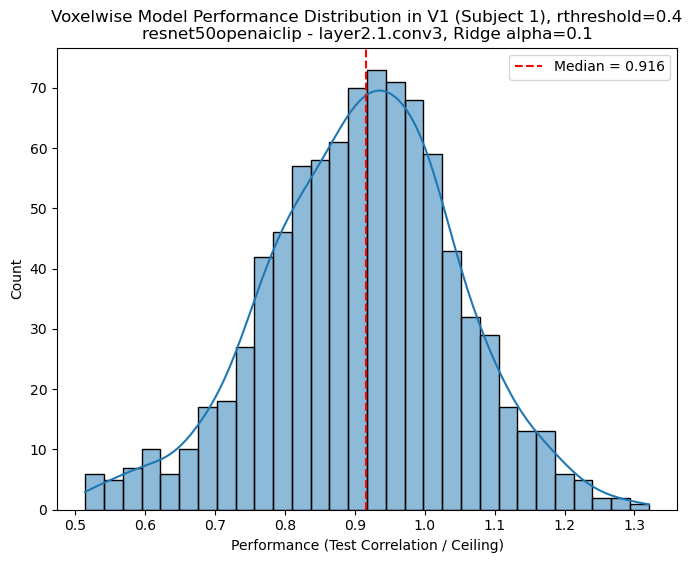

-----------------------------------------


Alpha: 1.0
Test Pearson's r: 0.513 ± 0.115
Test RDM correlation: 0.456


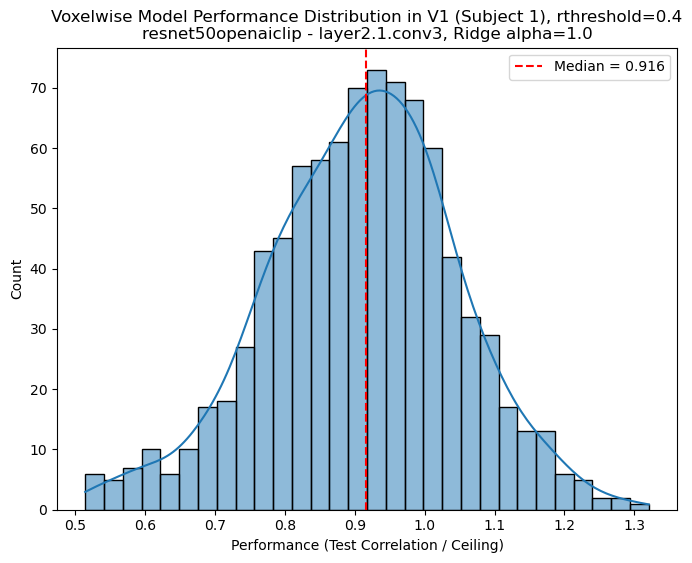

-----------------------------------------


Alpha: 10.0
Test Pearson's r: 0.513 ± 0.115
Test RDM correlation: 0.456


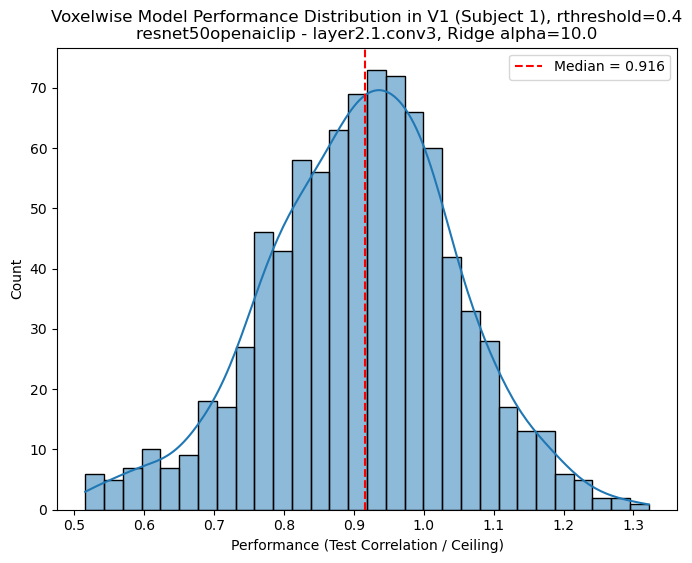

-----------------------------------------


Alpha: 100.0
Test Pearson's r: 0.515 ± 0.114
Test RDM correlation: 0.457


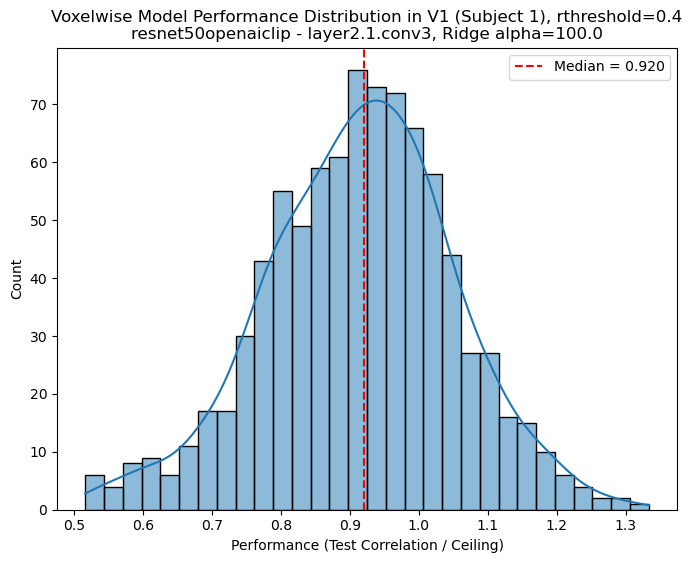

-----------------------------------------




In [68]:
x_train = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.NSD_DIR,
    model,
    layer,
    'nsd',
    subset=train_subset
)
x_test = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.NSD_DIR,
    model,
    layer,
    'nsd',
    subset=test_subset
)
# Flatten activations
x_train = x_train.flatten(start_dim=1)
x_test = x_test.flatten(start_dim=1)
print(f'Flattened train activations shape: {x_train.shape}')
print(f'Flattened test activations shape: {x_test.shape}')
# Move to CPU numpy arrays
x_train = x_train.cpu().numpy()
x_test = x_test.cpu().numpy()

for alpha in alphas:
    print(f'Alpha: {alpha}')
    trained_encoder, train_metrics, test_metrics = encode.fit_eval_mapper(
        Ridge(alpha=alpha),
        x_train,
        y_train,
        x_test,
        y_test,
        metric='all'
    )
    print(f"Test Pearson's r: {test_metrics['pearsonr'].mean():.3f} ± {test_metrics['pearsonr'].std():.3f}")
    print(f'Test RDM correlation: {test_metrics["rdmr"]:.3f}')
    # Plot performance per voxel
    voxelwise_test_univariate_corr = test_metrics['pearsonr']
    voxelwise_ceiling = voxel_reliabilities.copy()
    voxelwise_performance = voxelwise_test_univariate_corr / voxelwise_ceiling
    # Plot a distribution of voxelwise performance using searborn and make distribution plot
    # Also plot a line for median
    plt.figure(figsize=(8, 6))
    sns.histplot(voxelwise_performance, bins=30, kde=True)
    plt.axvline(np.median(voxelwise_performance), color='r', linestyle='--', label=f'Median = {np.median(voxelwise_performance):.3f}')
    plt.title(f'Voxelwise Model Performance in {froi} (Subject {subject})')
    plt.xlabel('Performance (Test Correlation / Ceiling)')
    plt.ylabel('Count')
    plt.title(f'Voxelwise Model Performance Distribution in {froi} (Subject {subject}), rthreshold={rthreshold}\n{model.name} - {layer}, Ridge alpha={alpha}')
    plt.legend()
    # plt.savefig(os.path.join(PLOTS_DIR, f'subject{subject}_{froi}_voxelwise_performance_distribution.png'))
    plt.show()
    print('-----------------------------------------\n\n')

Flattened train activations shape: torch.Size([485, 401408])
Flattened test activations shape: torch.Size([515, 401408])
Test Pearson's r: 0.513 ± 0.115
Test RDM correlation: 0.456


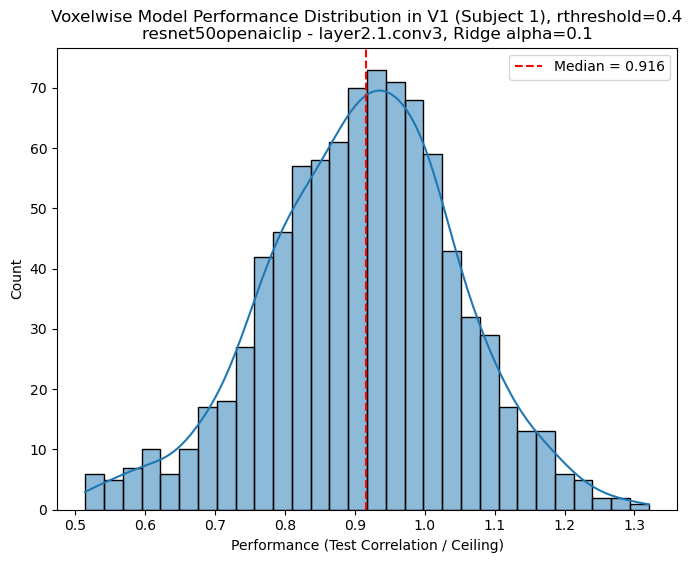

In [69]:
final_layer = 'layer2.1.conv3'
final_alpha = 0.1
x_train = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.NSD_DIR,
    model,
    final_layer,
    'nsd',
    subset=train_subset
)
x_test = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.NSD_DIR,
    model,
    final_layer,
    'nsd',
    subset=test_subset
)
# Flatten activations
x_train = x_train.flatten(start_dim=1)
x_test = x_test.flatten(start_dim=1)
print(f'Flattened train activations shape: {x_train.shape}')
print(f'Flattened test activations shape: {x_test.shape}')
# Move to CPU numpy arrays
x_train = x_train.cpu().numpy()
x_test = x_test.cpu().numpy()

trained_encoder, train_metrics, test_metrics = encode.fit_eval_mapper(
    Ridge(alpha=final_alpha),
    x_train,
    y_train,
    x_test,
    y_test,
    metric='all'
)
print(f"Test Pearson's r: {test_metrics['pearsonr'].mean():.3f} ± {test_metrics['pearsonr'].std():.3f}")
print(f'Test RDM correlation: {test_metrics["rdmr"]:.3f}')
# Plot performance per voxel
voxelwise_test_univariate_corr = test_metrics['pearsonr']
voxelwise_ceiling = voxel_reliabilities.copy()
voxelwise_performance = voxelwise_test_univariate_corr / voxelwise_ceiling
# Plot a distribution of voxelwise performance using searborn and make distribution plot
# Also plot a line for median
plt.figure(figsize=(8, 6))
sns.histplot(voxelwise_performance, bins=30, kde=True)
plt.axvline(np.median(voxelwise_performance), color='r', linestyle='--', label=f'Median = {np.median(voxelwise_performance):.3f}')
plt.title(f'Voxelwise Model Performance in {froi} (Subject {subject})')
plt.xlabel('Performance (Test Correlation / Ceiling)')
plt.ylabel('Count')
plt.title(f'Voxelwise Model Performance Distribution in {froi} (Subject {subject}), rthreshold={rthreshold}\n{model.name} - {final_layer}, Ridge alpha={final_alpha}')
plt.legend()
# plt.savefig(os.path.join(PLOTS_DIR, f'subject{subject}_{froi}_voxelwise_performance_distribution.png'))
plt.show()

In [70]:
trained_encoder

,alpha,0.1
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [71]:
# Utils
# Get end to end torch encoding model
class EM(torch.nn.Module):
    def __init__(self, model, layer, mapping_coef, mapping_intercept):
        super(EM, self).__init__()
        self.model = model
        self.layer = layer
        
        # Convert sklearn mapping to torch.nn.Linear
        n_features = mapping_coef.shape[1]
        n_outputs = mapping_coef.shape[0]
        self.mapping_layer = torch.nn.Linear(n_features, n_outputs)
        
        # Set weights and bias from the sklearn model
        self.mapping_layer.weight.data = torch.FloatTensor(mapping_coef)
        self.mapping_layer.bias.data = torch.FloatTensor(mapping_intercept)
        
        # Get the layer module
        self.layer_module = dict([*self.model.model.named_modules()])[self.layer]
        
        # Register a forward hook to get the activations
        self.activations = None
        def hook(module, input, output):
            self.activations = output
        self.layer_module.register_forward_hook(hook)
    
    def forward(self, x):
        _ = self.model(x)
        # Get the activations
        x = self.activations
        x = x.reshape(x.shape[0], -1)
        # Apply the mapping directly with torch Linear layer
        x_mapped = self.mapping_layer(x)
        return x_mapped

In [72]:
final_encoding_model = EM(
    model,
    final_layer,
    trained_encoder.coef_,
    trained_encoder.intercept_
)

In [86]:
from torch.utils.data import Dataset, DataLoader

class ImageDataset(Dataset):
    """Dataset for a single folder of images, without labels."""
    def __init__(self, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform
        # List all files and ensure they are images (e.g., .bmp, .png, .jpg)
        self.img_names = sorted([f for f in os.listdir(img_dir) if f.lower().endswith(('.bmp', '.png', '.jpg', '.jpeg'))])

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_names[idx])
        image = Image.open(img_path).convert("RGB")
        
        # We'll return the original filename along with the image.
        # This is very useful for inference tasks.
        filename = self.img_names[idx]

        if self.transform:
            image = self.transform(image)
            
        return image, filename

In [99]:
STIMULI_DIR = f'Experiment_Stimuli/Stimuli_MD'

dataset = ImageDataset(STIMULI_DIR, transform=model.transforms)

data_loader = DataLoader(
    dataset=dataset,
    batch_size=512,
    shuffle=False,      # IMPORTANT: Set to False for sequential processing
    num_workers=0
)

In [ ]:
predictions_dir = f'{RESULTS_DIR}/predictions/'
os.makedirs(predictions_dir, exist_ok=True)

em = final_encoding_model
em.eval()
with torch.no_grad():
    assert len(data_loader) == 1, "DataLoader should have only one batch for all images."
    for batch in data_loader:
        images, filenames = batch
        images = images
        preds = em(images)
# Convert filenames and preds to a csv with first column as filenames and rest as preds
preds = preds.cpu().numpy()
df = pd.DataFrame(preds)
df.insert(0, 'filename', filenames)
output_csv = f'{predictions_dir}/predictions_{froi}_r{rthreshold}_{subject}.csv'
df.to_csv(output_csv, index=False)
print(f'Saved predictions to {output_csv}')

In [108]:
v1_mean_acts_df = pd.DataFrame({
    'filename': df['filename'],
    'v1_mean_prediction': df.iloc[:, 1:].mean(axis=1)
})
# Convert to dict
v1_mean_acts = v1_mean_acts_df.set_index('filename')['v1_mean_prediction'].to_dict()

In [126]:
all_file_names = df['filename'].tolist()
all_orientations = np.unique([x.split('_')[1][3:] for x in all_file_names])
# all_conditions = np.unique([x.split('_')[2] for x in all_file_names])
v1_mean_acts_dict = {
    'Upright': {ori: [] for ori in all_orientations},
    'Inverted': {ori: [] for ori in all_orientations},
    'Scrambled': {ori: [] for ori in all_orientations}
}
for filename, meanact in v1_mean_acts.items():
    orientation = filename.split('_')[1][3:]
    assert orientation in all_orientations, f"Orientation {orientation} not recognized."
    if 'Int' in filename:
        v1_mean_acts_dict['Upright'][orientation].append(meanact)
    elif 'Inv' in filename:
        v1_mean_acts_dict['Inverted'][orientation].append(meanact)
    elif 'Scr' in filename:
        v1_mean_acts_dict['Scrambled'][orientation].append(meanact)

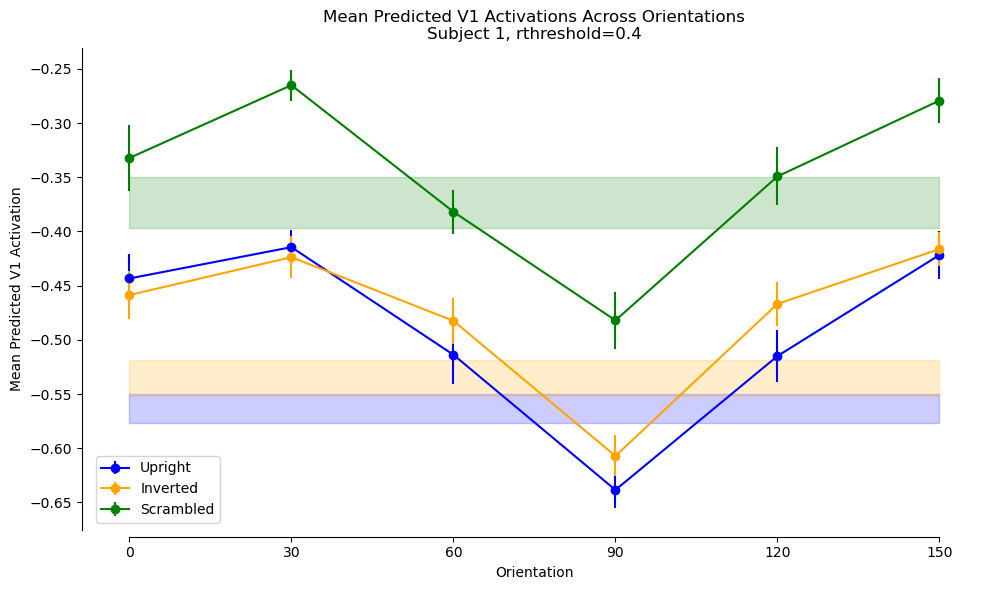

In [156]:
# Plot line plots of mean V1 activations across orientations for each condition
# Also make a shaded area for FS (full-spectrum) orintation
plt.figure(figsize=(10, 6))
numeric_orientations = all_orientations.copy()
numeric_orientations = np.delete(numeric_orientations, np.where(numeric_orientations == 'FS'))
# Order orientations numerically, no 'FS', keep the labels as string
numeric_orientations = sorted(numeric_orientations, key=lambda x: (float('inf') if x == 'FS' else int(x)))
for condition, color in zip(v1_mean_acts_dict.keys(), ['blue', 'orange', 'green']):
    mean_acts = []
    std_acts = []
    for orientation in numeric_orientations:
        acts = v1_mean_acts_dict[condition][orientation]
        mean_acts.append(np.mean(acts))
        std_acts.append(np.std(acts))
    mean_acts = np.array(mean_acts)
    std_acts = np.array(std_acts)
    # Plot line with points and yerrorbars (no shading)
    plt.errorbar(numeric_orientations, mean_acts, yerr=std_acts, label=condition, color=color, marker='o')
    # Shade FS orientation
    fs_acts = v1_mean_acts_dict[condition]['FS']
    fs_mean = np.mean(fs_acts)
    fs_std = np.std(fs_acts)
    plt.fill_between([0, len(numeric_orientations)-1], [fs_mean - fs_std], [fs_mean + fs_std], color=color, alpha=0.2)
plt.xticks(numeric_orientations)
plt.xlabel('Orientation')
plt.ylabel('Mean Predicted V1 Activation')
plt.title(f'Mean Predicted V1 Activations Across Orientations\nSubject {subject}, rthreshold={rthreshold}')
plt.legend()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['left'].set_bounds(plt.gca().get_ylim()[0], plt.gca().get_ylim()[1])
plt.gca().spines['bottom'].set_bounds(0, len(numeric_orientations)-1)
plt.tight_layout()
# plt.savefig(os.path.join(PLOTS_DIR, f'subject{subject}_{froi}_mean_v1_activations_across_orientations.png'))
plt.show()